# Projet ENMO : asymétrie entre le bras droit et le bras gauche

**Question :** la main dominante (droitier ou gaucher) crée-t-elle une différence d'accélération entre les deux bras, selon l'activité ?

**Protocole :** 2 participants (Daniel = gaucher, Said = droitier). Un capteur à chaque poignet (AX6 à gauche, AX3 à droite, 100 mesures par seconde). 4 tâches de 2 minutes : repos, écriture, clavier, marche.

**Étapes :** 1. charger les données → 2. vérifier la qualité → 3. corriger la calibration → 4. calculer l'ENMO → 5. calculer l'indice d'asymétrie → 6. graphiques → 7. interprétation

In [1]:
# Bibliothèques utilisées
import pandas as pd               # tableaux de données
import matplotlib.pyplot as plt   # graphiques

## Informations du protocole
Heures de début et de fin de chaque tâche, notées pendant les mesures.

In [2]:
taches = ["repos", "ecriture", "clavier", "marche"]

horaires = {
    "Daniel": {"repos": ("14:36", "14:38"), "ecriture": ("14:39", "14:41"),
               "clavier": ("14:43", "14:45"), "marche": ("14:47", "14:49")},
    "Said":   {"repos": ("15:07", "15:09"), "ecriture": ("15:10", "15:12"),
               "clavier": ("15:13", "15:15"), "marche": ("15:16", "15:18")},
}

## 1. Charger les données
Chaque fichier contient 4 colonnes : le temps, puis l'accélération sur les axes x, y et z (en g).

On calcule la **norme** du vecteur accélération : norme = √(x² + y² + z²).

In [3]:
def charger(fichier):
    df = pd.read_csv(fichier, header=None, names=["temps", "x", "y", "z"])
    df["temps"] = pd.to_datetime(df["temps"])
    df["heure"] = df["temps"].dt.strftime("%H:%M")    # ex : "14:36"
    df["norme"] = (df["x"]**2 + df["y"]**2 + df["z"]**2) ** 0.5
    return df

# Les 4 fichiers : un par participant et par poignet
donnees = {}
for participant in ["Daniel", "Said"]:
    for cote in ["gauche", "droite"]:
        donnees[(participant, cote)] = charger(f"data/{cote}_{participant}.csv")

donnees[("Said", "droite")].head()

,temps,x,y,z,heure,norme
0,2026-11-07 15:03:42.479,0.046875,-0.921875,-0.562500,15:03,1.080952
1,2026-11-07 15:03:42.490,0.031250,-0.859375,-0.625000,15:03,1.063074
2,2026-11-07 15:03:42.500,-0.031250,-0.828125,-0.656250,15:03,1.057086
3,2026-11-07 15:03:42.509,-0.046875,-0.781250,-0.625000,15:03,1.001586
4,2026-11-07 15:03:42.520,-0.031250,-0.828125,-0.546875,15:03,0.992895


## 2. Vérifier la qualité des données
- **Fréquence** : nombre de mesures par seconde (on attend environ 100).
- **Trous** : écarts de plus de 20 ms entre deux mesures (données perdues).
- **Valeurs manquantes** : cases vides dans le fichier.

In [4]:
for (participant, cote), df in donnees.items():
    ecarts = df["temps"].diff().dt.total_seconds()       # temps entre deux mesures (s)
    frequence = 1 / ecarts.mean()
    trous = (ecarts > 0.02).sum()
    manquantes = df.isna().sum().sum()
    print(f"{participant} {cote} : {len(df)} mesures, {frequence:.0f} Hz, "
          f"{trous} trous, {manquantes} valeurs manquantes")

Daniel gauche : 107040 mesures, 99 Hz, 0 trous, 0 valeurs manquantes
Daniel droite : 108720 mesures, 101 Hz, 0 trous, 0 valeurs manquantes
Said gauche : 88400 mesures, 99 Hz, 0 trous, 0 valeurs manquantes
Said droite : 89760 mesures, 101 Hz, 0 trous, 0 valeurs manquantes


Les 4 enregistrements sont complets : environ 100 Hz, aucun trou, aucune valeur manquante.

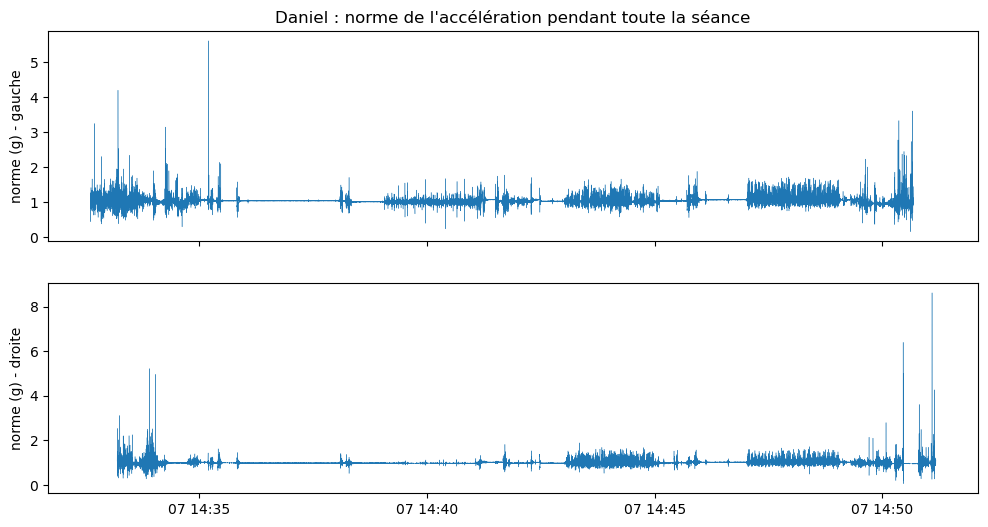

In [5]:
# Graphique du signal de Daniel pour voir les 4 tâches
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, cote in zip(axes, ["gauche", "droite"]):
    df = donnees[("Daniel", cote)]
    ax.plot(df["temps"], df["norme"], linewidth=0.3)
    ax.set_ylabel(f"norme (g) - {cote}")
axes[0].set_title("Daniel : norme de l'accélération pendant toute la séance")
plt.show()

## 3. Corriger la calibration
Au repos, le capteur ne mesure que la gravité : la norme devrait valoir **exactement 1 g**.
Ce n'est pas le cas : le capteur gauche (AX6) mesure un peu plus de 1 g et le droit (AX3) un peu moins.

Sans correction, le bras gauche paraîtrait toujours plus actif, même au repos : ce serait une **fausse asymétrie**.

**Correction :** on divise la norme par sa valeur moyenne au repos. Après correction, le repos vaut 1 g.

In [6]:
for (participant, cote), df in donnees.items():
    debut, fin = horaires[participant]["repos"]
    pendant_repos = (df["heure"] >= debut) & (df["heure"] < fin)

    # Avant correction : norme moyenne au repos (devrait valoir 1 g)
    norme_repos = df.loc[pendant_repos, "norme"].mean()

    # Correction : on divise toutes les mesures par cette valeur
    df["norme_corrigee"] = df["norme"] / norme_repos

    # Après correction : on vérifie que le repos vaut bien 1 g
    norme_repos_apres = df.loc[pendant_repos, "norme_corrigee"].mean()

    print(f"{participant} {cote} : norme au repos avant = {norme_repos:.3f} g  ->  "
          f"après = {norme_repos_apres:.3f} g")

Daniel gauche : norme au repos avant = 1.040 g  ->  après = 1.000 g
Daniel droite : norme au repos avant = 0.981 g  ->  après = 1.000 g
Said gauche : norme au repos avant = 1.027 g  ->  après = 1.000 g
Said droite : norme au repos avant = 0.949 g  ->  après = 1.000 g


Après correction, la norme au repos vaut 1,000 g pour les 4 capteurs. Ce n'est pas une preuve que la correction est parfaite : on a calculé le facteur **à partir du repos**, donc le repos vaut forcément 1 g après. Cela vérifie seulement que le calcul a bien été fait.

**Limite :** le facteur est calculé dans une seule position (bras posé sur la table). Dans d'autres positions du poignet, une petite erreur de quelques pourcents peut rester, car l'erreur réelle du capteur est différente sur chaque axe.

## 4. Calculer l'ENMO
**ENMO = norme − 1 g**, et on remplace les valeurs négatives par 0.

On enlève 1 g pour retirer la gravité : il ne reste que l'accélération due au mouvement. Le résultat est exprimé en **mg** (milli-g, 1 g = 1000 mg).

In [7]:
for df in donnees.values():
    df["enmo_brut"] = (df["norme"] - 1).clip(lower=0) * 1000          # sans correction
    df["enmo"] = (df["norme_corrigee"] - 1).clip(lower=0) * 1000      # avec correction

## 5. Calculer l'indice d'asymétrie
Pour chaque personne et chaque tâche, on compare **ses deux poignets** :

**Indice = (ENMO droit − ENMO gauche) / (ENMO droit + ENMO gauche)**

- **0** : les deux bras bougent autant
- **proche de +1** : le bras droit bouge plus
- **proche de −1** : le bras gauche bouge plus

In [8]:
def enmo_moyen(participant, cote, tache, colonne="enmo"):
    df = donnees[(participant, cote)]
    debut, fin = horaires[participant][tache]
    pendant_tache = (df["heure"] >= debut) & (df["heure"] < fin)
    return df.loc[pendant_tache, colonne].mean()

lignes = []
for participant in ["Daniel", "Said"]:
    for tache in taches:
        # Avec correction
        D = enmo_moyen(participant, "droite", tache)
        G = enmo_moyen(participant, "gauche", tache)
        # Sans correction
        D_brut = enmo_moyen(participant, "droite", tache, "enmo_brut")
        G_brut = enmo_moyen(participant, "gauche", tache, "enmo_brut")
        lignes.append({
            "participant": participant,
            "tache": tache,
            "ENMO gauche avant (mg)": round(G_brut, 1),
            "ENMO gauche après (mg)": round(G, 1),
            "ENMO droit avant (mg)": round(D_brut, 1),
            "ENMO droit après (mg)": round(D, 1),
            "indice avant": round((D_brut - G_brut) / (D_brut + G_brut), 2),
            "indice après": round((D - G) / (D + G), 2),
        })

resultats = pd.DataFrame(lignes)
resultats

,participant,tache,ENMO gauche avant (mg),ENMO gauche après (mg),ENMO droit avant (mg),ENMO droit après (mg),indice avant,indice après
0,Daniel,repos,39.8,1.1,0.0,3.2,-1.00,0.49
1,Daniel,ecriture,20.7,6.8,0.5,2.0,-0.96,-0.55
2,Daniel,clavier,36.0,17.6,34.4,42.0,-0.02,0.41
3,Daniel,marche,114.8,85.4,68.4,80.9,-0.25,-0.03
4,Said,repos,27.3,1.2,0.0,1.9,-1.00,0.21
5,Said,ecriture,22.3,3.4,12.3,31.6,-0.29,0.81
6,Said,clavier,29.9,13.4,6.9,23.5,-0.62,0.27
7,Said,marche,177.7,155.5,78.2,108.4,-0.39,-0.18


## 6. Graphiques

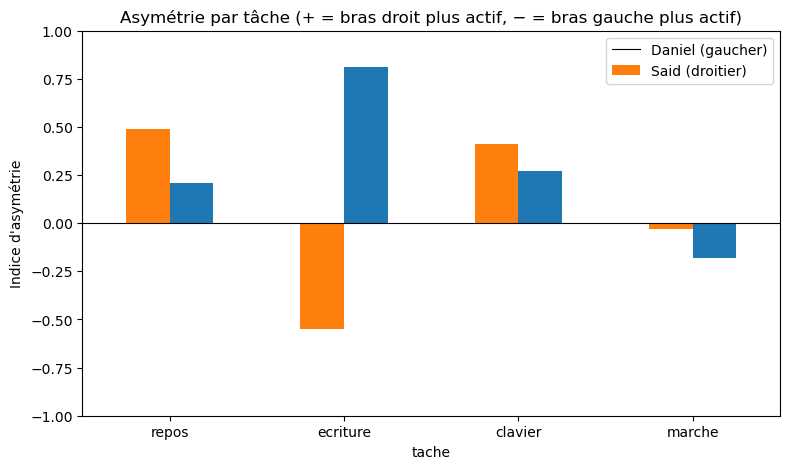

In [9]:
# Indice d'asymétrie par tâche : Daniel (gaucher) et Said (droitier) côte à côte
indices = resultats.pivot(index="tache", columns="participant", values="indice après").loc[taches]

ax = indices.plot.bar(figsize=(9, 5), rot=0, color=["tab:orange", "tab:blue"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylim(-1, 1)
ax.set_ylabel("Indice d'asymétrie")
ax.set_title("Asymétrie par tâche (+ = bras droit plus actif, − = bras gauche plus actif)")
ax.legend(["Daniel (gaucher)", "Said (droitier)"])
plt.savefig("figures/indice_asymetrie.png", dpi=150)
plt.show()

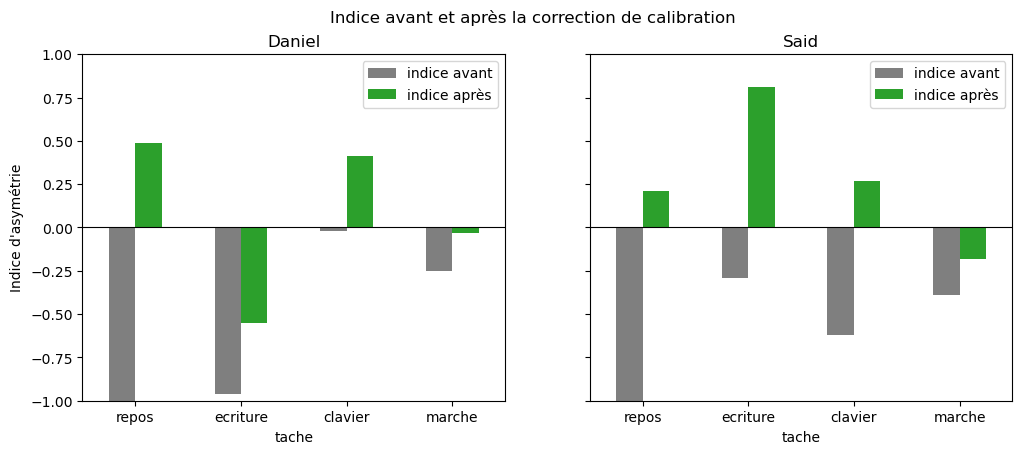

In [10]:
# Effet de la correction : indice avant et après, pour chaque participant
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, participant in zip(axes, ["Daniel", "Said"]):
    tableau = resultats[resultats["participant"] == participant].set_index("tache")
    tableau[["indice avant", "indice après"]].plot.bar(ax=ax, rot=0, color=["tab:gray", "tab:green"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_ylim(-1, 1)
    ax.set_title(participant)
axes[0].set_ylabel("Indice d'asymétrie")
fig.suptitle("Indice avant et après la correction de calibration")
plt.savefig("figures/avant_apres_correction.png", dpi=150)
plt.show()

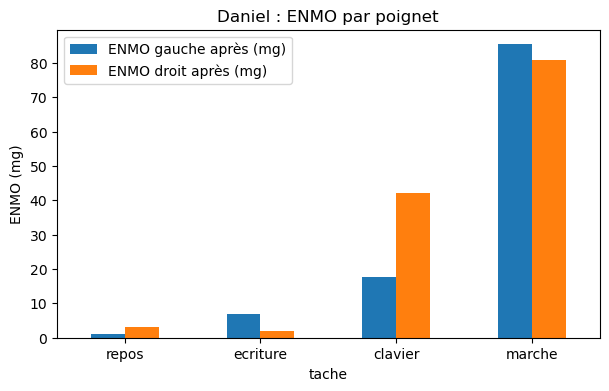

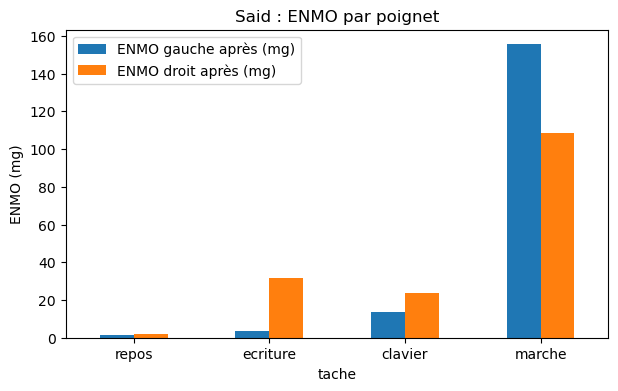

In [11]:
# ENMO de chaque poignet après correction, pour chaque participant
for participant in ["Daniel", "Said"]:
    tableau = resultats[resultats["participant"] == participant].set_index("tache")
    ax = tableau[["ENMO gauche après (mg)", "ENMO droit après (mg)"]].plot.bar(figsize=(7, 4), rot=0)
    ax.set_ylabel("ENMO (mg)")
    ax.set_title(f"{participant} : ENMO par poignet")
    plt.savefig(f"figures/enmo_{participant}.png", dpi=150)
    plt.show()

## 7. Interprétation

- **Écriture :** l'indice est **négatif chez Daniel (gaucher)** et **positif chez Said (droitier)**. On observe l'inversion attendue : c'est la main dominante qui fait le mouvement.
- **Marche :** l'indice est proche de 0, les deux bras se balancent de façon presque symétrique.
- **Clavier :** les deux participants penchent vers la droite (utilisation de la souris ? capteur AX3 moins précis ?). À discuter.
- **Repos :** l'ENMO ne vaut que quelques mg, c'est surtout du bruit. L'indice n'est pas interprétable quand D + G est presque nul.
- **Sans correction de calibration** (colonnes « avant »), le bras gauche recevait des mg « fantômes » et toutes les tâches semblaient pencher vers la gauche. Pour Said, l'indice de l'écriture change même de signe (−0,29 avant, +0,81 après). Vérifier la qualité des données était donc indispensable.

**Limites :** seulement 2 participants, une seule mesure par tâche, deux modèles de capteurs différents, correction de calibration simplifiée (un seul facteur, calculé dans une seule position).

## 8. Application santé
Mesurer l'utilisation de chaque bras dans la vie quotidienne sert au suivi des patients après un AVC (le bras atteint est moins utilisé), à l'évaluation de troubles moteurs et à la rééducation. Un indice d'asymétrie calculé chaque semaine permettrait de suivre la récupération d'un patient.